In [409]:
import numpy as np 
import pandas as pd 

import seaborn as sns 
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder , OrdinalEncoder
from sklearn.impute import SimpleImputer


In [410]:
df = pd.read_csv("Apartments Prices Dataset.csv")
df.head(15)

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux
5,"1,560,000 EGP",140 m²,3 rooms,1 bathroom,9,2014,Broker,Side Street,"11,143 EGP/M²",Cash,Extra Super Lux
6,"6,329,000 EGP",145 m²,3 rooms,3 bathroom,2,2027,Broker,Other,"43,648 EGP/M²",Installments,Semi Finished
7,"4,209,000 EGP",133 m²,2 rooms,2 bathroom,3,2025,Broker,Lake,"31,647 EGP/M²",Cash or Installments,Extra Super Lux
8,"2,600,000 EGP",145 m²,3 rooms,2 bathroom,2,2025,Broker,Side Street,"17,931 EGP/M²",Cash,Super Lux
9,"631,250 EGP",125 m²,3 rooms,2 bathroom,4,2019,Developer,Main Street,"5,050 EGP/M²",Cash or Installments,Semi Finished


In [411]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           5578 non-null   object
 1   area_sqm        5578 non-null   object
 2   rooms           5578 non-null   object
 3   bathrooms       5578 non-null   object
 4   floor_level     5578 non-null   object
 5   year_built      5578 non-null   int64 
 6   seller_type     5578 non-null   object
 7   view            5578 non-null   object
 8   price_per_sqm   5578 non-null   object
 9   payment_method  5578 non-null   object
 10  finishing_type  5578 non-null   object
dtypes: int64(1), object(10)
memory usage: 479.5+ KB


In [412]:
df.describe()

,year_built
count,5578.000000
mean,2022.327178
std,8.431095
min,1915.000000
25%,2023.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


In [413]:
df.isna().sum()

price             0
area_sqm          0
rooms             0
bathrooms         0
floor_level       0
year_built        0
seller_type       0
view              0
price_per_sqm     0
payment_method    0
finishing_type    0
dtype: int64

In [414]:
df["price"].value_counts()

price
6,500,000 EGP     94
7,500,000 EGP     91
6,000,000 EGP     85
4,500,000 EGP     83
3,500,000 EGP     74
                  ..
4,695,000 EGP      1
8,584,000 EGP      1
14,800,000 EGP     1
3,130,000 EGP      1
6,329,000 EGP      1
Name: count, Length: 1321, dtype: int64

In [415]:
df["price"] = df["price"].str.replace("EGP" , "", regex = False  )
df["price"] = df["price"].astype("string").str.replace("," , "", regex = False)
df["price"] = df["price"].str.strip().astype(float)
df["price"].value_counts().head()

price
6500000.0    94
7500000.0    91
6000000.0    85
4500000.0    83
3500000.0    74
Name: count, dtype: int64

In [416]:
df["area_sqm"].value_counts()

area_sqm
140 m²    174
150 m²    154
200 m²    149
130 m²    148
160 m²    128
         ... 
370 m²      1
218 m²      1
264 m²      1
393 m²      1
285 m²      1
Name: count, Length: 251, dtype: int64

In [417]:
df["area_sqm"] = df["area_sqm"].str.replace("m²" , "" , regex = False).str.strip().astype(float)
df["area_sqm"].value_counts().head()

area_sqm
140.0    174
150.0    154
200.0    149
130.0    148
160.0    128
Name: count, dtype: int64

In [418]:
df['bathrooms'] = df['bathrooms'].str.replace("bathroom" , "" , regex = False).str.strip().astype(int)
df['rooms'] = df['rooms'].str.replace("rooms" , "" , regex = False).str.strip().astype(int)

In [419]:
print(df['bathrooms'].value_counts().head()) 
print("*" * 50)
print(df['rooms'].value_counts().head())

bathrooms
1    1969
2    1855
3    1628
4     113
5       8
Name: count, dtype: int64
**************************************************
rooms
3    3099
2    1350
1     825
4     272
5      26
Name: count, dtype: int64


In [420]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000.0,120.0,2,3,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,3250000.0,162.0,3,2,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,2650000.0,122.0,3,1,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,12720000.0,212.0,4,3,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,5898000.0,135.0,2,1,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [421]:
df.dtypes

price             float64
area_sqm          float64
rooms               int64
bathrooms           int64
floor_level        object
year_built          int64
seller_type        object
view               object
price_per_sqm      object
payment_method     object
finishing_type     object
dtype: object

In [422]:
df["floor_level"].value_counts()

floor_level
1         1831
2         1319
3          860
4          498
5          276
Ground     170
7          133
6          125
9           98
8           68
10          57
13          41
11          41
12          29
15           8
16           7
14           6
18           6
64           2
22           1
17           1
32           1
Name: count, dtype: int64

In [423]:
df["floor_level"] = df["floor_level"].str.replace("Ground", "0" , regex= False).str.strip().astype(int)
df["floor_level"].value_counts()

floor_level
1     1831
2     1319
3      860
4      498
5      276
0      170
7      133
6      125
9       98
8       68
10      57
13      41
11      41
12      29
15       8
16       7
14       6
18       6
64       2
22       1
17       1
32       1
Name: count, dtype: int64

In [424]:
df.drop("price_per_sqm" , axis = 1 , inplace = True )

In [425]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,payment_method,finishing_type
0,2163000.0,120.0,2,3,3,2025,Developer,Main Street,Installments,Semi Finished
1,3250000.0,162.0,3,2,6,2024,Developer,Main Street,Cash or Installments,Semi Finished
2,2650000.0,122.0,3,1,4,2024,Developer,Main Street,Cash or Installments,Semi Finished
3,12720000.0,212.0,4,3,13,2027,Broker,Club,Cash or Installments,Extra Super Lux
4,5898000.0,135.0,2,1,6,2025,Developer,Lake,Cash or Installments,Super Lux


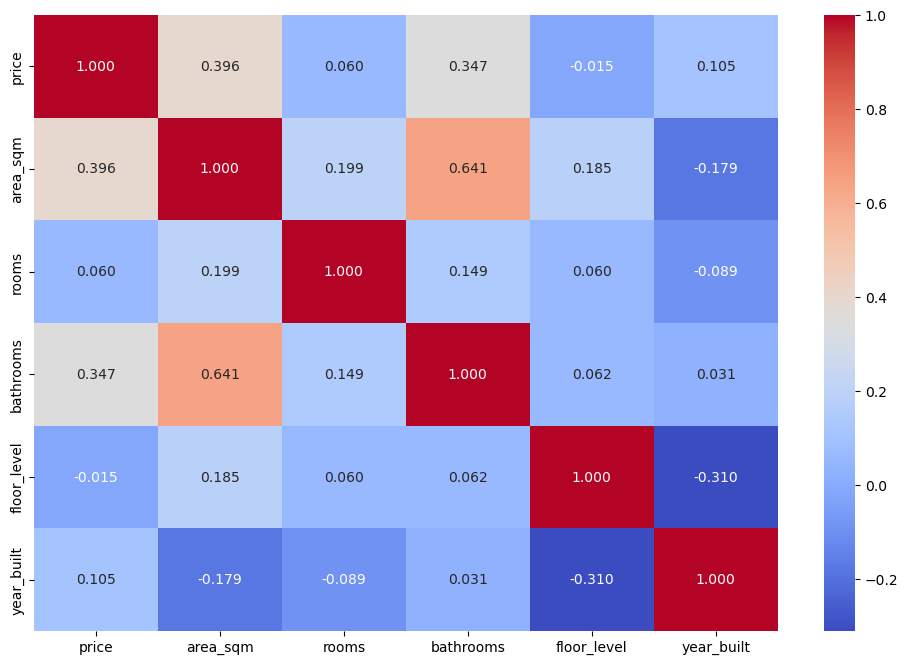

In [426]:
plt.figure(figsize = (12,8))
sns.heatmap(df.corr(numeric_only= True ) ,annot = True , fmt = ".3f", cmap = "coolwarm")
plt.show()

In [427]:
df["finishing_type"].value_counts()

finishing_type
Super Lux          2264
Semi Finished      1355
Extra Super Lux    1295
Without Finish      503
Lux                 161
Name: count, dtype: int64

In [428]:
X = df.drop('price', axis=1)
y = df['price']

In [429]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [437]:
data_encoding = df.select_dtypes("object").columns
data_encoding

Index(['seller_type', 'view', 'payment_method', 'finishing_type'], dtype='object')

In [443]:
encoding = OrdinalEncoder()
X_train[data_encoding] = encoding.fit_transform(X_train[data_encoding])
X_test[data_encoding] = encoding.transform(X_test[data_encoding])

In [444]:
X_train.head()

,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,payment_method,finishing_type
2100,210.0,3,2,1,2020,0.0,6.0,0.0,2.0
1168,120.0,2,1,1,2015,4.0,8.0,0.0,3.0
1983,58.0,1,1,1,2026,0.0,10.0,2.0,3.0
3994,128.0,2,3,4,2027,0.0,3.0,2.0,0.0
3799,177.0,4,4,2,2028,0.0,3.0,1.0,2.0


In [472]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [473]:
from sklearn.tree import DecisionTreeRegressor , plot_tree 

In [474]:
model = DecisionTreeRegressor(
    criterion = 'squared_error', 
    
    max_depth = 5 , 
    
    min_samples_split = 10 , 
    
    min_samples_leaf = 5,

    min_impurity_decrease = 0.01 , 

    ccp_alpha = .1,

    random_state = 100
    
)

In [475]:
model.fit(X_train_scaled , y_train)

DecisionTreeRegressor(ccp_alpha=0.1, max_depth=5, min_impurity_decrease=0.01,
                      min_samples_leaf=5, min_samples_split=10,
                      random_state=100)

In [476]:
y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

In [477]:
from sklearn.metrics import r2_score

In [478]:
train = r2_score(y_train ,y_pred_train )
test = r2_score(y_test , y_pred_test)
print(train ,  test)

0.3923022470240217 0.11941865313455136


In [504]:
from sklearn.model_selection import GridSearchCV

In [506]:
grid_parm = {
    "criterion": ["squared_error", "absolute_error"],
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "ccp_alpha": [0.0, 0.01, 0.1],   
}

In [508]:
grid = GridSearchCV(estimator= model , param_grid = grid_parm , cv = 5 , scoring="r2")

In [510]:
grid.fit(X_train_scaled , y_train)

GridSearchCV(cv=5,
             estimator=DecisionTreeRegressor(ccp_alpha=0.1, max_depth=5,
                                             min_impurity_decrease=0.01,
                                             min_samples_leaf=5,
                                             min_samples_split=10,
                                             random_state=100),
             param_grid={'ccp_alpha': [0.0, 0.01, 0.1],
                         'criterion': ['squared_error', 'absolute_error'],
                         'max_depth': [3, 5, 10, None],
                         'min_samples_leaf': [1, 2, 5],
                         'min_samples_split': [2, 5, 10]},
             scoring='r2')

In [512]:
y_pred_train = grid.predict(X_train_scaled)
y_pred_test = grid.predict(X_test_scaled)

In [514]:
train = r2_score(y_train ,y_pred_train )
test = r2_score(y_test , y_pred_test)
print(train ,  test)

0.7187905237699065 0.21691519420363548
